# Laboratorio 7 — Algoritmo neurogenético: HydroGrowNet Batavia
**Kevin Osmar Valdez Meza — 1288703**

**Objetivo de la práctica:** proponer una arquitectura de red neuronal (MLP feedforward entrenada con backpropagation/Adam) y optimizar sus parámetros con un algoritmo genético.

**Objetivo del dataset:** predecir el **peso total de cosecha (g)** de lechugas Batavia en hidroponía a partir de medidas físicas de la planta. En el Laboratorio 4 la red ya obtuvo R² = 0.917, así que aquí la pregunta es crítica: ¿el GA puede mejorar una red que ya funciona bien, o la mejora es marginal?

Flujo del notebook: (1) análisis exploratorio → (2) red base del Laboratorio 4 → (3) algoritmo genético → (4) red optimizada → (5) comparación.

> Todos los parámetros editables (población, generaciones, mutación, espacio de búsqueda, red base) están en `configuracion.py`.

In [1]:
import json, random
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
import configuracion as cfg
from redes import *
from GAneuro import GA
import graficas as gr
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 20)
print('Parametros del GA:', cfg.GA_PARAMS)

Parametros del GA: {'num_inv': 24, 'max_generaciones': 20, 'torneo': 3, 'prob_mutacion': 0.15, 'por_remplazo': 0.3, 'folds': 3}


## 1. Análisis exploratorio de los datos

In [2]:
df, X, y, grupos = cargar_hydro()
print('Plantas útiles:', len(df), '| Experimentos:', df.experimento.nunique())
print(df.isna().sum())
display(df.head(8))
df.describe().T

Plantas útiles: 222 | Experimentos: 3
total_weight     0
plant_height     0
shoot_length     0
root_length      0
head_diameter    6
stem_diameter    0
leaves           0
experimento      0
dtype: int64


,total_weight,plant_height,shoot_length,root_length,head_diameter,stem_diameter,leaves,experimento
0,243.0000,42.0000,13.5000,28.5000,25.5000,1.7000,210.0000,1
1,241.0000,54.0000,10.5000,43.5000,27.0000,2.0000,200.0000,1
2,251.0000,62.0000,13.5000,48.5000,26.2500,2.0000,212.0000,1
3,200.0000,55.0000,13.5000,41.5000,26.0000,2.0000,185.0000,1
4,200.0000,66.0000,14.0000,52.0000,27.5000,2.0000,178.0000,1
5,209.0000,60.0000,13.0000,47.0000,23.2500,1.5000,176.0000,1
6,252.0000,67.0000,16.0000,51.0000,26.0000,2.0000,211.0000,1
7,229.0000,67.0000,13.5000,53.5000,26.0000,2.0000,193.0000,1


,count,mean,std,min,25%,50%,75%,max
total_weight,222.0000,284.6948,55.7610,150.0000,241.9375,279.0000,326.7500,412.0000
plant_height,222.0000,62.0443,9.2257,23.0000,56.0000,62.0000,68.0000,100.0000
shoot_length,222.0000,16.6036,2.8665,10.0000,14.0000,17.0000,19.0000,23.0000
root_length,222.0000,45.4407,8.4083,13.0000,40.0000,45.0000,50.3750,83.0000
head_diameter,216.0000,27.8310,2.4016,22.0000,26.0000,27.5000,29.5000,35.0000
stem_diameter,222.0000,1.6420,0.4643,0.7000,1.0000,2.0000,2.0000,2.5000
leaves,222.0000,248.3690,53.4150,111.0000,209.0000,244.0000,289.5000,368.0000
experimento,222.0000,2.0270,0.8234,1.0000,1.0000,2.0000,3.0000,3.0000


### ¿Qué es y qué variables tiene?
HydroGrowNet: tres experimentos de cultivo hidropónico de lechuga Batavia con mediciones de cada planta al cosechar (se leen las hojas *Harvest* de los tres archivos Excel).

| Variable | Significado | Unidad |
|---|---|---|
| `plant_height` | altura de la planta | cm |
| `shoot_length` | longitud del brote | cm |
| `root_length` | longitud de la raíz | cm |
| `stem_diameter` | diámetro del tallo | cm |
| `leaves` | número de hojas | — |
| `head_diameter` | diámetro de la cabeza (6 nulos, se imputan con la mediana) | cm |
| **`total_weight`** | **peso total de la planta — salida** | g |

En el Lab 4 se usaron 5 entradas; `head_diameter` se dejó fuera por tener nulos. Aquí se incluye como candidata y el GA decide si se usa.

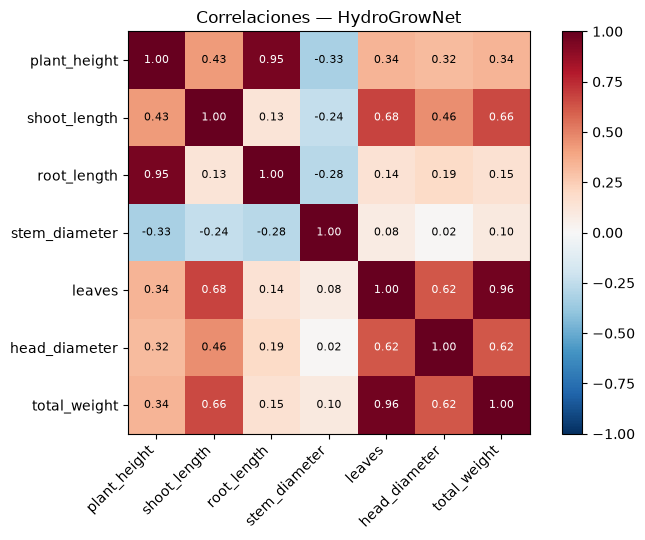

,correlación con el peso
leaves,0.9636
shoot_length,0.6586
head_diameter,0.6204
plant_height,0.3418
root_length,0.1505
stem_diameter,0.0997


In [3]:
num = ['plant_height', 'shoot_length', 'root_length', 'stem_diameter', 'leaves', 'head_diameter', 'total_weight']
corr = gr.mapa_correlacion(df, num, 'Correlaciones — HydroGrowNet', 'hydro_correlacion')
corr['total_weight'].drop('total_weight').sort_values(ascending=False).to_frame('correlación con el peso')

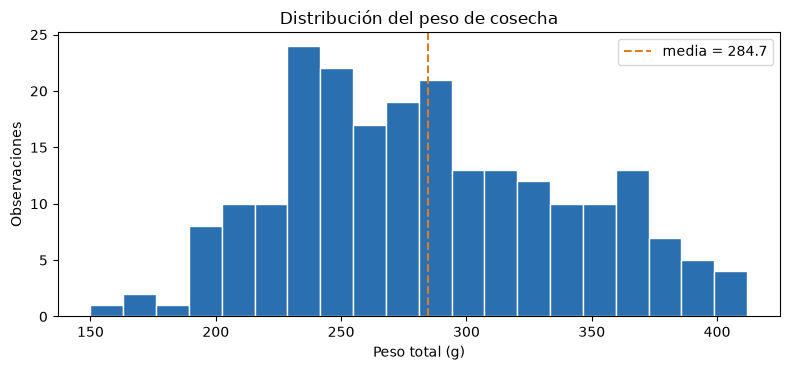

Peso: media=284.7, desviación=55.8, min=150, max=412 g


In [4]:
gr.histograma(df.total_weight, 'Peso total (g)', 'Distribución del peso de cosecha', 'hydro_histograma')
print(f"Peso: media={df.total_weight.mean():.1f}, desviación={df.total_weight.std():.1f}, min={df.total_weight.min():.0f}, max={df.total_weight.max():.0f} g")

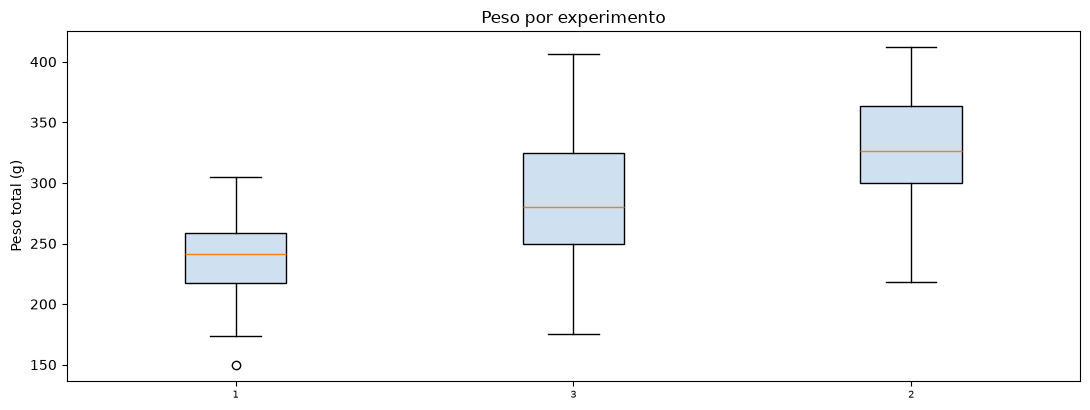

,count,mean,std
experimento,,,
1,72,239.4167,31.1357
2,72,327.7917,43.3476
3,78,286.7083,51.3786


In [5]:
gr.cajas_por_grupo(df, 'experimento', 'total_weight', 'Peso total (g)', 'Peso por experimento', 'hydro_experimento', rotar=0)
df.groupby('experimento').total_weight.agg(['count', 'mean', 'std'])

**Observaciones del análisis:**
- Solo 222 plantas útiles: dataset pequeño, por lo que la red debe evitar sobreajuste (la regularización `alpha` es importante).
- `leaves` tiene una correlación muy alta con el peso (~0.96): casi toda la información está en una sola variable. `shoot_length` también aporta (~0.66).
- `root_length` y `stem_diameter` casi no se relacionan con el peso; son candidatas a ser descartadas por el GA.
- El peso medio cambia entre experimentos, pero las medidas de la planta ya reflejan esa diferencia.

## 2. Red neuronal base (Laboratorio 4)
Se reproduce exactamente la red del Laboratorio 4 con la misma división **60 % entrenamiento / 40 % prueba** (`random_state=42`). Se guardan la métrica de rendimiento (R², R, MAE, RMSE) y la pérdida: `loss_final` es la pérdida de entrenamiento del último epoch (MSE escalado) y `MSE` es la pérdida total en el conjunto de prueba en unidades reales.

In [6]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=cfg.TEST_SIZE, random_state=cfg.SEMILLA_RED)
print('Entrenamiento:', len(Xtr), '| Prueba:', len(Xte))
base = cfg.BASE_HYDRO
mod_base, pred_base, m_base = entrenar_y_evaluar(base, grupos, Xtr, ytr, Xte, yte)
kf = KFold(cfg.GA_PARAMS['folds'], shuffle=True, random_state=cfg.SEMILLA_RED)
cv_base = cross_val_score(crear_red(base), Xtr[columnas(base, grupos)], ytr, cv=kf, scoring='r2').mean()
print('Red base:', describir(base, grupos))
print('Variables:', base['variables'])
print(f'Aptitud de la red base (R2 validacion cruzada en entrenamiento) = {cv_base:.4f}')
pd.Series(m_base, name='Red base').to_frame()

Entrenamiento: 133 | Prueba: 89


Red base: 5-32-16-8-1 | relu | lr=0.001 | alpha=0.0001 | batch=auto
Variables: ['plant_height', 'shoot_length', 'root_length', 'stem_diameter', 'leaves']
Aptitud de la red base (R2 validacion cruzada en entrenamiento) = 0.8859


,Red base
R2,0.9173
R,0.9580
MAE,11.1914
RMSE,16.5084
MSE,272.5258
loss_final,0.0295
epocas,368.0000
parametros,865.0000


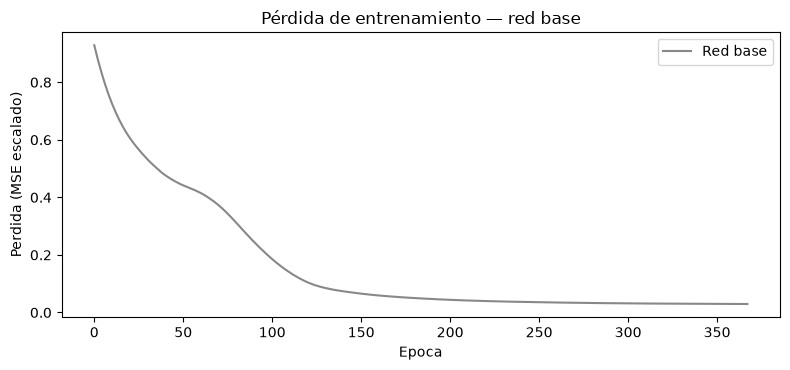

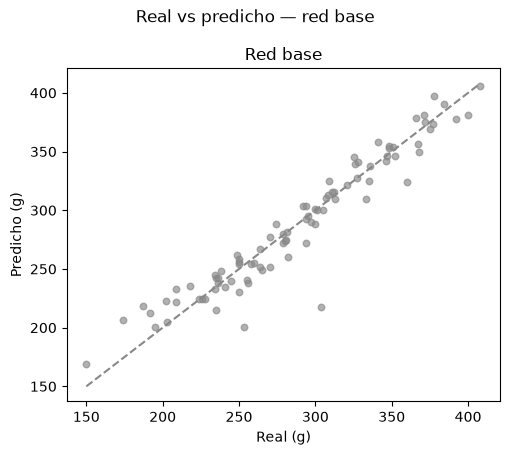

In [7]:
gr.curva_perdida([('Red base', mod_base.regressor_['nn'].loss_curve_, gr.GRIS)], 'Pérdida de entrenamiento — red base', 'hydro_perdida_base')
gr.real_vs_predicho(yte.values, [('Red base', pred_base, gr.GRIS)], 'g', 'Real vs predicho — red base', 'hydro_real_pred_base')

## 3. Algoritmo genético
Se reutiliza la estructura de los laboratorios 5 y 6: cromosoma, aptitud, selección por **torneo de 3**, **cruce de un punto**, mutación y **elitismo**. La diferencia es que cada cromosoma ahora representa una red neuronal completa.

**Cromosoma (genes enteros):** cada gen guarda el índice de una opción. Los primeros 8 genes describen la red (número de capas, neuronas por capa, activación, tasa de aprendizaje, regularización L2 `alpha` y tamaño de lote) y los siguientes son bits 0/1 que indican si se usa cada variable de entrada.

**Aptitud:** R² promedio de validación cruzada de 3 pliegues, calculado **solo con el 60 % de entrenamiento**. El 40 % de prueba no se toca durante la búsqueda, así la comparación final es justa. Si un cromosoma no usa ninguna variable recibe aptitud −1.

In [8]:
nombres, opciones = genes_del_problema(grupos)
valores = [str(v) for v in cfg.ESPACIO_RED.values()] + ['0 = no usar, 1 = usar'] * len(grupos)
pd.DataFrame({'gen': range(1, len(nombres) + 1), 'nombre': nombres, 'n_opciones': opciones, 'valores': valores})

,gen,nombre,n_opciones,valores
0,1,capas,3,"[1, 2, 3]"
1,2,neuronas1,6,"[4, 8, 16, 32, 64, 128]"
2,3,neuronas2,6,"[4, 8, 16, 32, 64, 128]"
3,4,neuronas3,6,"[4, 8, 16, 32, 64, 128]"
4,5,activacion,3,"['relu', 'tanh', 'logistic']"
5,6,tasa_aprendizaje,6,"[0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03]"
6,7,alpha,8,"[1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 3.0, 10.0]"
7,8,batch,4,"[16, 32, 64, 128]"
8,9,usar_plant_height,2,"0 = no usar, 1 = usar"
9,10,usar_shoot_length,2,"0 = no usar, 1 = usar"


In [9]:
random.seed(cfg.SEMILLA)
ga = GA(Xtr, ytr, grupos, **cfg.GA_PARAMS)
mejor, historial = ga.buscar_solucion(cfg.GA_PARAMS['max_generaciones'])
print('\nRedes distintas entrenadas y evaluadas:', len(ga.evaluar.cache))
print('Mejor cromosoma:', mejor.cadena(), '| aptitud =', round(mejor.score, 4))

[00] mejor R2_cv=0.9184 | promedio=0.4624 | 2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e-05 | batch=16 | 26.6s


[01] mejor R2_cv=0.9184 | promedio=0.7596 | 2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e-05 | batch=16 | 10.4s


[02] mejor R2_cv=0.9184 | promedio=0.7701 | 2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e-05 | batch=16 | 9.0s


[03] mejor R2_cv=0.9233 | promedio=0.7826 | 2-8-1 | relu | lr=0.0003 | alpha=0.001 | batch=64 | 7.7s


[04] mejor R2_cv=0.9263 | promedio=0.8097 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 14.4s


[05] mejor R2_cv=0.9263 | promedio=0.8660 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 10.7s


... (11 outputs left out)

[17] mejor R2_cv=0.9263 | promedio=0.9086 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 7.0s


[18] mejor R2_cv=0.9263 | promedio=0.8894 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 12.3s


[19] mejor R2_cv=0.9263 | promedio=0.7828 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 5.3s


[20] mejor R2_cv=0.9263 | promedio=0.8419 | 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64 | 9.6s

Redes distintas entrenadas y evaluadas: 331
Mejor cromosoma: 0-1-4-3-0-2-2-2-0-0-0-1-1-0 | aptitud = 0.9263


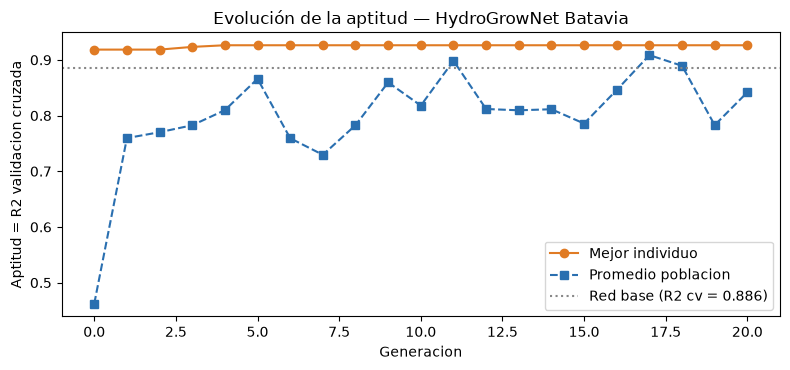

,generacion,mejor,promedio,cromosoma,red
0,0,0.9184,0.4624,2-3-4-3-2-1-0-0-0-0-0-0-1-1,2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e...
1,1,0.9184,0.7596,2-3-4-3-2-1-0-0-0-0-0-0-1-1,2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e...
2,2,0.9184,0.7701,2-3-4-3-2-1-0-0-0-0-0-0-1-1,2-32-64-32-1 | logistic | lr=0.0003 | alpha=1e...
3,3,0.9233,0.7826,0-1-4-3-0-1-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.0003 | alpha=0.001 | batch=64
4,4,0.9263,0.8097,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
5,5,0.9263,0.8660,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
6,6,0.9263,0.7593,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
7,7,0.9263,0.7296,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
8,8,0.9263,0.7827,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
9,9,0.9263,0.8596,0-1-4-3-0-2-2-2-0-0-0-1-1-0,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64


In [10]:
hist = pd.DataFrame(historial)
gr.evolucion_ga(historial, 'Evolución de la aptitud — HydroGrowNet Batavia', 'hydro_evolucion_ga', base_cv=cv_base)
hist

In [11]:
# Cinco mejores redes distintas de la ultima generacion
vistos, filas = set(), []
for crom in sorted(ga.poblacion, key=lambda c: c.score, reverse=True):
    if crom.clave() in vistos: continue
    vistos.add(crom.clave()); p = decodificar(crom.genes, grupos)
    filas.append({'cromosoma': crom.cadena(), 'R2_cv': crom.score, 'red': describir(p, grupos), 'variables': ', '.join(p['variables'])})
    if len(filas) == 5: break
pd.DataFrame(filas)

,cromosoma,R2_cv,red,variables
0,0-1-4-3-0-2-2-2-0-0-0-1-1-0,0.9263,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64,"stem_diameter, leaves"
1,0-1-4-2-0-2-2-2-0-0-0-1-1-0,0.9263,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64,"stem_diameter, leaves"
2,0-1-1-2-0-2-2-2-0-0-0-1-1-0,0.9263,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64,"stem_diameter, leaves"
3,0-2-4-3-0-2-4-2-0-0-0-1-1-0,0.9180,2-16-1 | relu | lr=0.001 | alpha=0.1 | batch=64,"stem_diameter, leaves"
4,0-4-3-1-0-2-2-2-0-1-0-0-1-1,0.9154,3-64-1 | relu | lr=0.001 | alpha=0.001 | batch=64,"shoot_length, leaves, head_diameter"


## 4. Red neuronal con parámetros optimizados
Se decodifica el mejor cromosoma, se entrena con todo el 60 % y se evalúa una sola vez con el 40 % de prueba.

In [12]:
opt = decodificar(mejor.genes, grupos)
mod_opt, pred_opt, m_opt = entrenar_y_evaluar(opt, grupos, Xtr, ytr, Xte, yte)
print('Red optimizada:', describir(opt, grupos))
print('Variables elegidas por el GA:', opt['variables'])
print('Variables descartadas:', [g for g in grupos if g not in opt['variables']])
pd.Series(m_opt, name='Red GA').to_frame()

Red optimizada: 2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64
Variables elegidas por el GA: ['stem_diameter', 'leaves']
Variables descartadas: ['plant_height', 'shoot_length', 'root_length', 'head_diameter']


,Red GA
R2,0.8650
R,0.9641
MAE,15.2857
RMSE,21.0910
MSE,444.8305
loss_final,0.0213
epocas,199.0000
parametros,33.0000


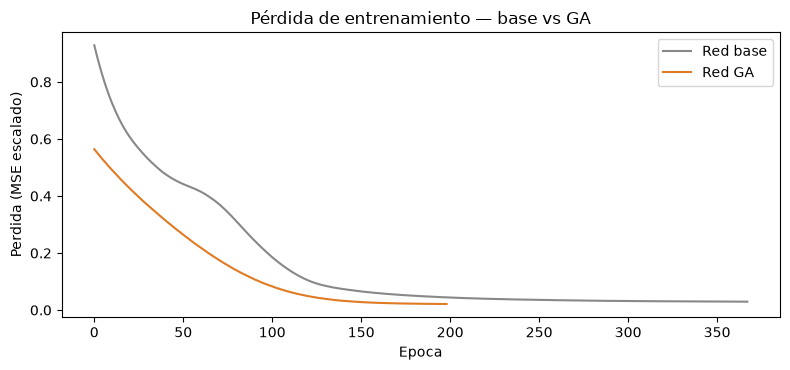

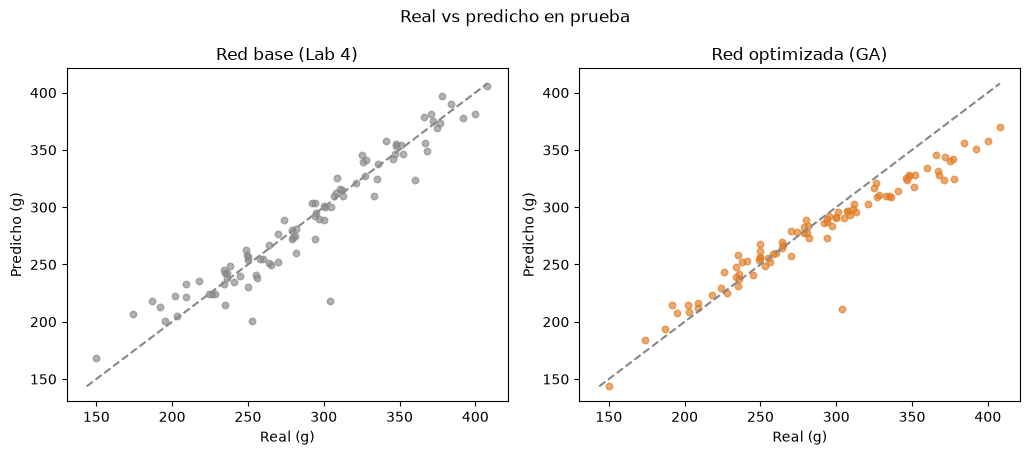

In [13]:
gr.curva_perdida([('Red base', mod_base.regressor_['nn'].loss_curve_, gr.GRIS), ('Red GA', mod_opt.regressor_['nn'].loss_curve_, gr.NARANJA)], 'Pérdida de entrenamiento — base vs GA', 'hydro_perdida_comparacion')
gr.real_vs_predicho(yte.values, [('Red base (Lab 4)', pred_base, gr.GRIS), ('Red optimizada (GA)', pred_opt, gr.NARANJA)], 'g', 'Real vs predicho en prueba', 'hydro_real_pred_comparacion')

## 5. Comparación entre las dos propuestas
Para separar el efecto de **qué variables se usan** del efecto de **cómo es la red**, se agrega un modelo intermedio: la arquitectura base del Lab 4 pero con las variables que eligió el GA.

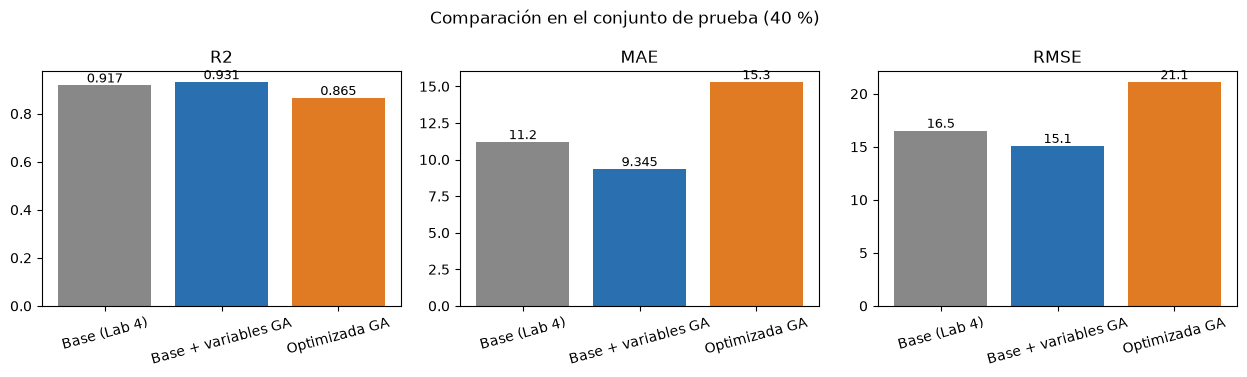

,R2,R,MAE,RMSE,MSE,loss_final,epocas,parametros,arquitectura
Base (Lab 4),0.9173,0.9580,11.1914,16.5084,272.5258,0.0295,368,865,5-32-16-8-1 | relu | lr=0.001 | alpha=0.0001 |...
Base + variables GA,0.9310,0.9673,9.3446,15.0787,227.3685,0.0346,194,769,2-32-16-8-1 | relu | lr=0.001 | alpha=0.0001 |...
Optimizada GA,0.8650,0.9641,15.2857,21.0910,444.8305,0.0213,199,33,2-8-1 | relu | lr=0.001 | alpha=0.001 | batch=64


In [14]:
intermedia = dict(base, variables=opt['variables'])
_, _, m_int = entrenar_y_evaluar(intermedia, grupos, Xtr, ytr, Xte, yte)
tabla = pd.DataFrame([m_base, m_int, m_opt], index=['Base (Lab 4)', 'Base + variables GA', 'Optimizada GA'])
tabla['arquitectura'] = [describir(base, grupos), describir(intermedia, grupos), describir(opt, grupos)]
gr.barras_comparacion(tabla, ['R2', 'MAE', 'RMSE'], 'Comparación en el conjunto de prueba (40 %)', 'hydro_comparacion')
tabla

### Robustez
Un solo entrenamiento puede salir bien o mal por suerte en la inicialización de pesos. Se repite el entrenamiento con 10 semillas distintas (misma división de datos).

In [15]:
rob_base = robustez(base, grupos, Xtr, ytr, Xte, yte)
rob_int = robustez(intermedia, grupos, Xtr, ytr, Xte, yte)
rob_opt = robustez(opt, grupos, Xtr, ytr, Xte, yte)
rob = pd.DataFrame({'Base R2': rob_base.R2, 'Base+vars R2': rob_int.R2, 'GA R2': rob_opt.R2, 'Base MAE': rob_base.MAE, 'Base+vars MAE': rob_int.MAE, 'GA MAE': rob_opt.MAE})
display(rob.describe().loc[['mean', 'std', 'min', 'max']])
mejora = (m_base['MAE'] - m_opt['MAE']) / m_base['MAE'] * 100
print(f"R2: {m_base['R2']:.4f} -> {m_opt['R2']:.4f} | MAE: {m_base['MAE']:.2f} -> {m_opt['MAE']:.2f} g ({mejora:.1f} % menos error)")

,Base R2,Base+vars R2,GA R2,Base MAE,Base+vars MAE,GA MAE
mean,0.9205,0.9269,0.9386,11.0649,9.6848,8.6024
std,0.0102,0.0187,0.0083,0.7333,2.0323,0.7801
min,0.9060,0.8870,0.9201,10.2407,7.8583,7.5363
max,0.9324,0.9516,0.9474,12.1383,14.8791,9.8291


R2: 0.9173 -> 0.8650 | MAE: 11.19 -> 15.29 g (-36.6 % menos error)


In [16]:
res = {'dataset': 'HydroGrowNet Batavia', 'n': int(len(df)), 'n_train': int(len(Xtr)), 'n_test': int(len(Xte)),
       'base': {**m_base, 'red': describir(base, grupos), 'variables': base['variables'], 'cv': float(cv_base)},
       'intermedia': {**m_int, 'red': describir(intermedia, grupos)},
       'optimizada': {**m_opt, 'red': describir(opt, grupos), 'variables': opt['variables'], 'cv': float(mejor.score), 'cromosoma': mejor.cadena()},
       'robustez': {'base_mean': float(rob_base.R2.mean()), 'base_std': float(rob_base.R2.std()), 'int_mean': float(rob_int.R2.mean()), 'int_std': float(rob_int.R2.std()), 'opt_mean': float(rob_opt.R2.mean()), 'opt_std': float(rob_opt.R2.std()),
                    'base_mae': float(rob_base.MAE.mean()), 'int_mae': float(rob_int.MAE.mean()), 'opt_mae': float(rob_opt.MAE.mean())},
       'historial': historial, 'redes_evaluadas': len(ga.evaluar.cache), 'ga': cfg.GA_PARAMS}
json.dump(res, open('resultados_hydro.json', 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
print('Resultados guardados en resultados_hydro.json')

Resultados guardados en resultados_hydro.json


## Conclusión
Con la semilla 42 la red del GA obtuvo R² = 0.865, peor que la base (0.917). Sin embargo, al repetir el entrenamiento con 10 semillas, la red del GA obtiene en promedio 0.939 ± 0.008 contra 0.920 ± 0.010 de la base, y su MAE promedio baja de 11.06 g a 8.60 g (22 % menos error). Es decir, la semilla 42 resultó ser una inicialización desfavorable para una red tan pequeña, y una sola corrida no era representativa.

En este dataset la mejora en precisión es pequeña, como se esperaba de una red que ya funcionaba bien, pero el GA encontró una red mucho más simple, más estable y que confirma lo que sugería el análisis exploratorio: el número de hojas concentra casi toda la información.

Comparar con una sola corrida puede llevar a conclusiones opuestas: con la semilla 42, en HydroGrowNet la red del GA parecía peor, y en Soybean el modelo intermedio parecía mejor. Al repetir con 10 semillas ambas conclusiones se invierten. Por eso la aptitud se calculó con validación cruzada y la comparación final con varias semillas.